In [2]:
print("Hello")
import pandas as pd
import numpy as np

Hello


In [3]:
df1=pd.read_excel("./online_retail_II.xlsx",sheet_name='Year 2009-2010')
df2=pd.read_excel("./online_retail_II.xlsx",sheet_name='Year 2010-2011')

In [4]:
df=pd.concat([df1,df2],ignore_index=True)
df.head()
df.shape

(1067371, 8)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[us]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 65.1+ MB


In [6]:
df=df.dropna(subset='Customer ID')
df.info()

<class 'pandas.DataFrame'>
Index: 824364 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      824364 non-null  object        
 1   StockCode    824364 non-null  object        
 2   Description  824364 non-null  object        
 3   Quantity     824364 non-null  int64         
 4   InvoiceDate  824364 non-null  datetime64[us]
 5   Price        824364 non-null  float64       
 6   Customer ID  824364 non-null  float64       
 7   Country      824364 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 56.6+ MB


In [7]:
df=df[~df['Invoice'].astype(str).str.startswith('C')]
df.info()


<class 'pandas.DataFrame'>
Index: 805620 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      805620 non-null  object        
 1   StockCode    805620 non-null  object        
 2   Description  805620 non-null  object        
 3   Quantity     805620 non-null  int64         
 4   InvoiceDate  805620 non-null  datetime64[us]
 5   Price        805620 non-null  float64       
 6   Customer ID  805620 non-null  float64       
 7   Country      805620 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 55.3+ MB


In [8]:
df=df[df['Quantity']>0]
df.shape

(805620, 8)

In [9]:
df=df[df['Price']>0]
df.shape

(805549, 8)

In [10]:
df['Month']=df['InvoiceDate'].dt.to_period('M').astype(str)
df['Month']
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Month
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,2009-12
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,2009-12
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,2009-12
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,2009-12
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,2009-12


In [11]:
import matplotlib.pyplot as plt

In [12]:
df['Revenue']=df['Quantity']*df['Price']
df.head()


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Month,Revenue
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,2009-12,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,2009-12,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,2009-12,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,2009-12,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,2009-12,30.0


In [13]:
df.info()

<class 'pandas.DataFrame'>
Index: 805549 entries, 0 to 1067370
Data columns (total 10 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      805549 non-null  object        
 1   StockCode    805549 non-null  object        
 2   Description  805549 non-null  object        
 3   Quantity     805549 non-null  int64         
 4   InvoiceDate  805549 non-null  datetime64[us]
 5   Price        805549 non-null  float64       
 6   Customer ID  805549 non-null  float64       
 7   Country      805549 non-null  str           
 8   Month        805549 non-null  str           
 9   Revenue      805549 non-null  float64       
dtypes: datetime64[us](1), float64(3), int64(1), object(3), str(2)
memory usage: 67.6+ MB


In [14]:
montly_revenue=df.groupby('Month')['Revenue'].sum().sort_index()
montly_revenue.index

Index(['2009-12', '2010-01', '2010-02', '2010-03', '2010-04', '2010-05',
       '2010-06', '2010-07', '2010-08', '2010-09', '2010-10', '2010-11',
       '2010-12', '2011-01', '2011-02', '2011-03', '2011-04', '2011-05',
       '2011-06', '2011-07', '2011-08', '2011-09', '2011-10', '2011-11',
       '2011-12'],
      dtype='str', name='Month')

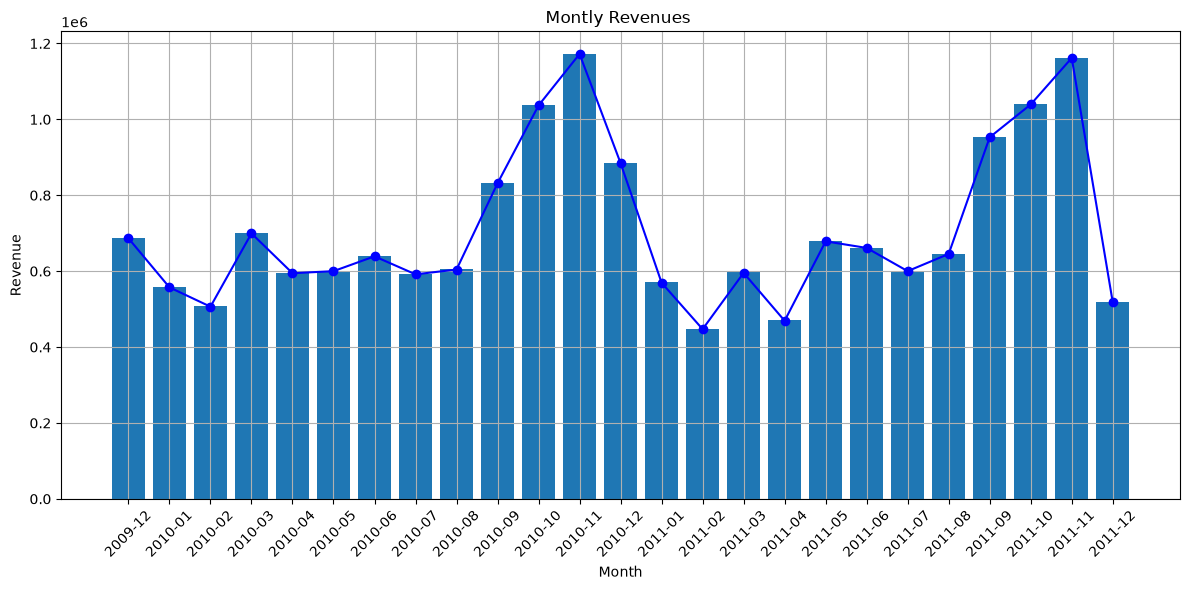

In [15]:
#provide height and width 
plt.figure(figsize=(12,6))
#plot Line
plt.bar(montly_revenue.index,montly_revenue.values+1000)
plt.plot(montly_revenue.index,montly_revenue.values,marker='o',color='Blue')
plt.title("Montly Revenues ")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.grid(True)
plt.show()



In [16]:
sample_df=df.sample(1000,random_state=1)
sample_df.shape
sample_df.info()

<class 'pandas.DataFrame'>
Index: 1000 entries, 860936 to 241534
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   Invoice      1000 non-null   object        
 1   StockCode    1000 non-null   object        
 2   Description  1000 non-null   object        
 3   Quantity     1000 non-null   int64         
 4   InvoiceDate  1000 non-null   datetime64[us]
 5   Price        1000 non-null   float64       
 6   Customer ID  1000 non-null   float64       
 7   Country      1000 non-null   str           
 8   Month        1000 non-null   str           
 9   Revenue      1000 non-null   float64       
dtypes: datetime64[us](1), float64(3), int64(1), object(3), str(2)
memory usage: 85.9+ KB


In [17]:
sample_df.head()


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Month,Revenue
860936,566288,23236,STORAGE TIN VINTAGE DOILY,6,2011-09-11 15:18:00,2.89,12883.0,United Kingdom,2011-09,17.34
1009407,577516,51014L,"FEATHER PEN,LIGHT PINK",12,2011-11-20 13:08:00,0.39,16533.0,United Kingdom,2011-11,4.68
904439,569670,23507,MINI PLAYING CARDS BUFFALO BILL,1,2011-10-05 13:47:00,0.42,14730.0,United Kingdom,2011-10,0.42
298927,518505,37471,MULTICOLOUR DOTS PLATE,684,2010-08-09 13:10:00,0.10,14277.0,France,2010-08,68.40
245386,513123,22425,ENAMEL COLANDER CREAM,3,2010-06-22 10:24:00,4.95,12359.0,Cyprus,2010-06,14.85


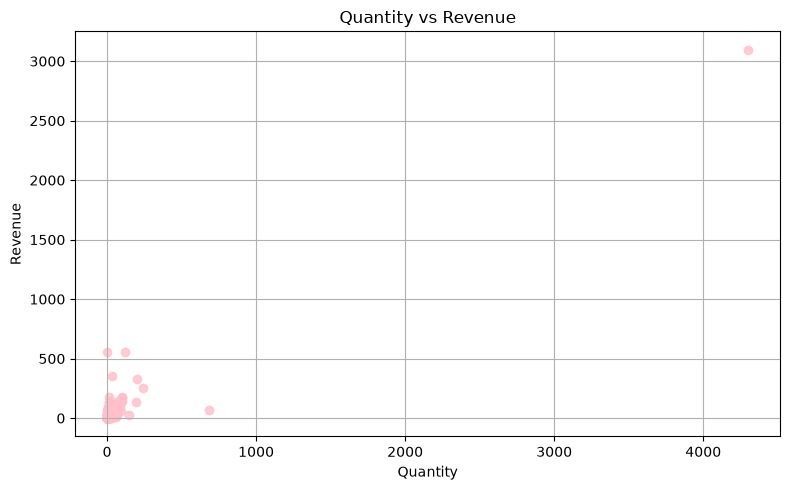

In [18]:
plt.figure(figsize=(8,5))
plt.scatter(sample_df.Quantity,sample_df.Revenue,alpha=0.8,color='Pink')
plt.xlabel("Quantity")
plt.ylabel("Revenue")
plt.title("Quantity vs Revenue")
plt.grid(True)
plt.tight_layout()
plt.show()

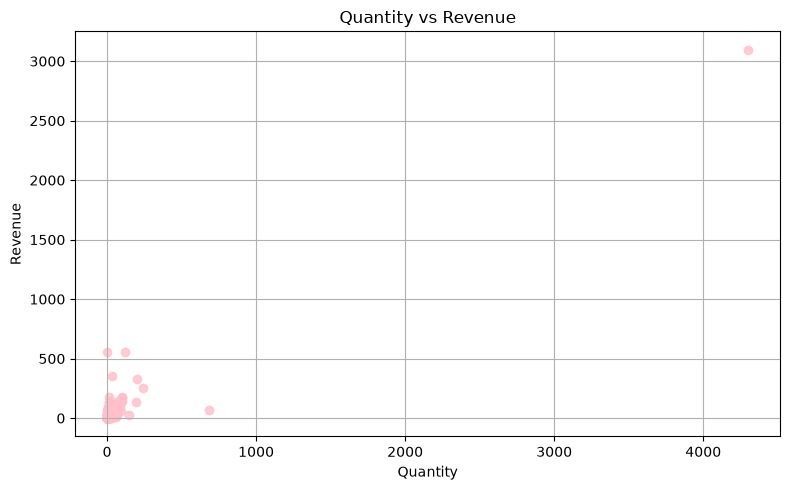

In [19]:
plt.figure(figsize=(8,5))
plt.scatter(sample_df['Quantity'],sample_df['Revenue'],alpha=0.8,color='Pink')
plt.xlabel("Quantity")
plt.ylabel("Revenue")
plt.title("Quantity vs Revenue")
plt.grid(True)
plt.tight_layout()
plt.show()

In [20]:
import seaborn as sns

In [21]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Month,Revenue
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,2009-12,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,2009-12,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,2009-12,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,2009-12,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,2009-12,30.0


In [22]:
Quantity_df=df[(df["Quantity"]>0) & (df["Quantity"]<100)]
Quantity_df.shape
Quantity_df.info()

<class 'pandas.DataFrame'>
Index: 792377 entries, 0 to 1067370
Data columns (total 10 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      792377 non-null  object        
 1   StockCode    792377 non-null  object        
 2   Description  792377 non-null  object        
 3   Quantity     792377 non-null  int64         
 4   InvoiceDate  792377 non-null  datetime64[us]
 5   Price        792377 non-null  float64       
 6   Customer ID  792377 non-null  float64       
 7   Country      792377 non-null  str           
 8   Month        792377 non-null  str           
 9   Revenue      792377 non-null  float64       
dtypes: datetime64[us](1), float64(3), int64(1), object(3), str(2)
memory usage: 66.5+ MB


In [23]:
Quantity_df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Month,Revenue
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,2009-12,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,2009-12,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,2009-12,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,2009-12,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,2009-12,30.0


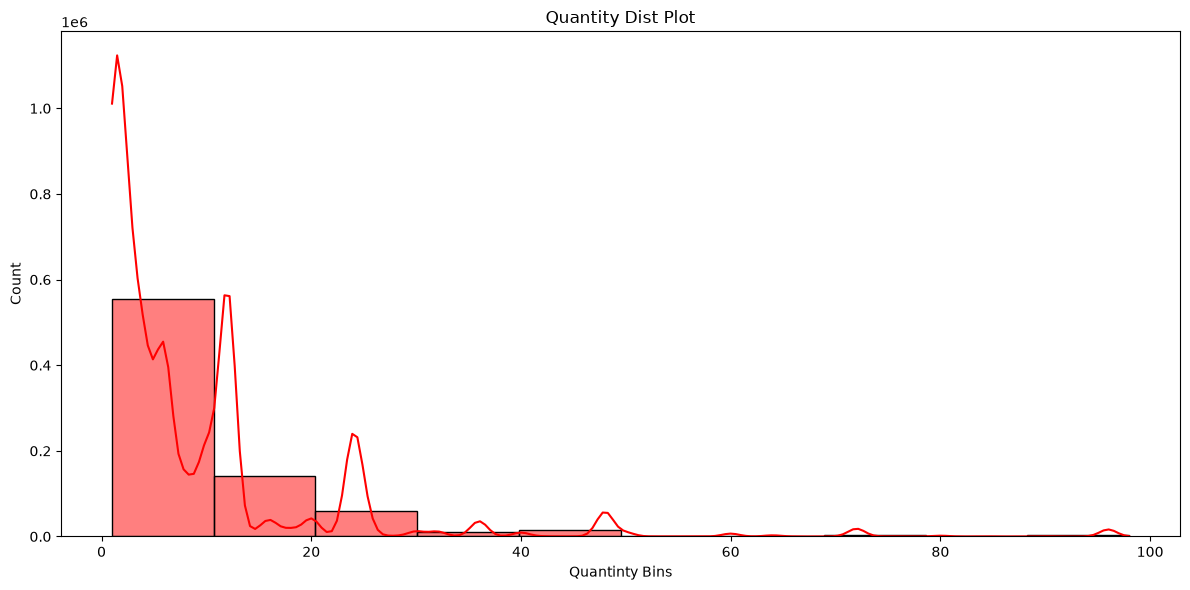

In [24]:
plt.figure(figsize=(12,6))
sns.histplot(Quantity_df['Quantity'],bins=10,kde=True,color='Red')
plt.title("Quantity Dist Plot")
plt.xlabel("Quantinty Bins")
plt.ylabel('Count')
plt.tight_layout()
plt.show()


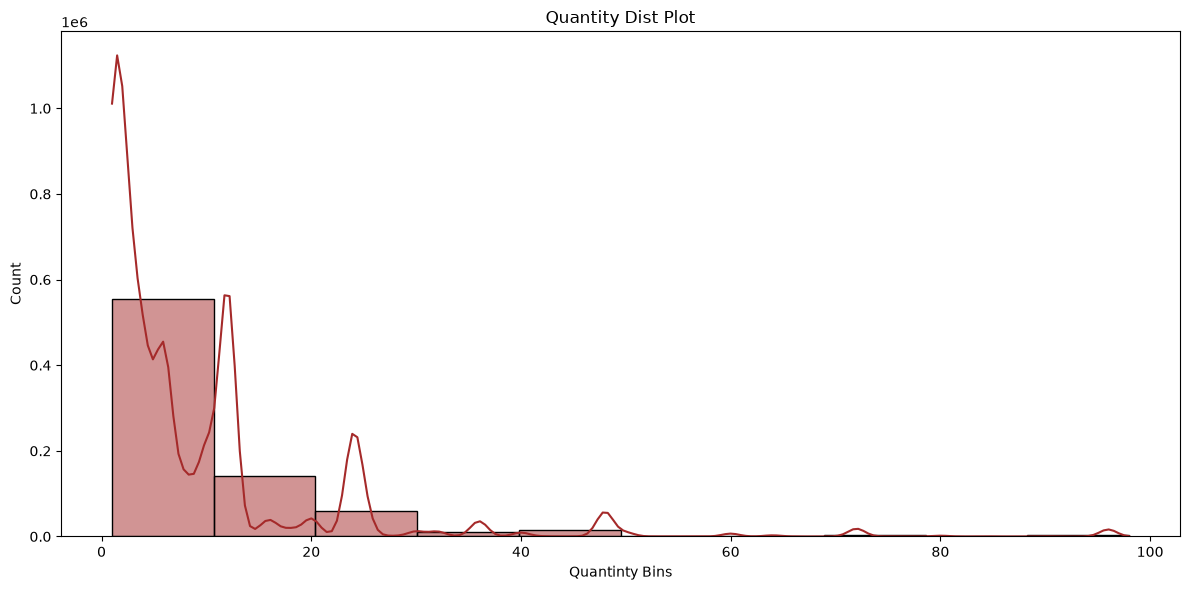

In [25]:
plt.figure(figsize=(12,6))
sns.histplot(Quantity_df['Quantity'],bins=10,kde=True,color='Brown')
plt.title("Quantity Dist Plot")
plt.xlabel("Quantinty Bins")
plt.ylabel('Count')
plt.tight_layout()
plt.show()

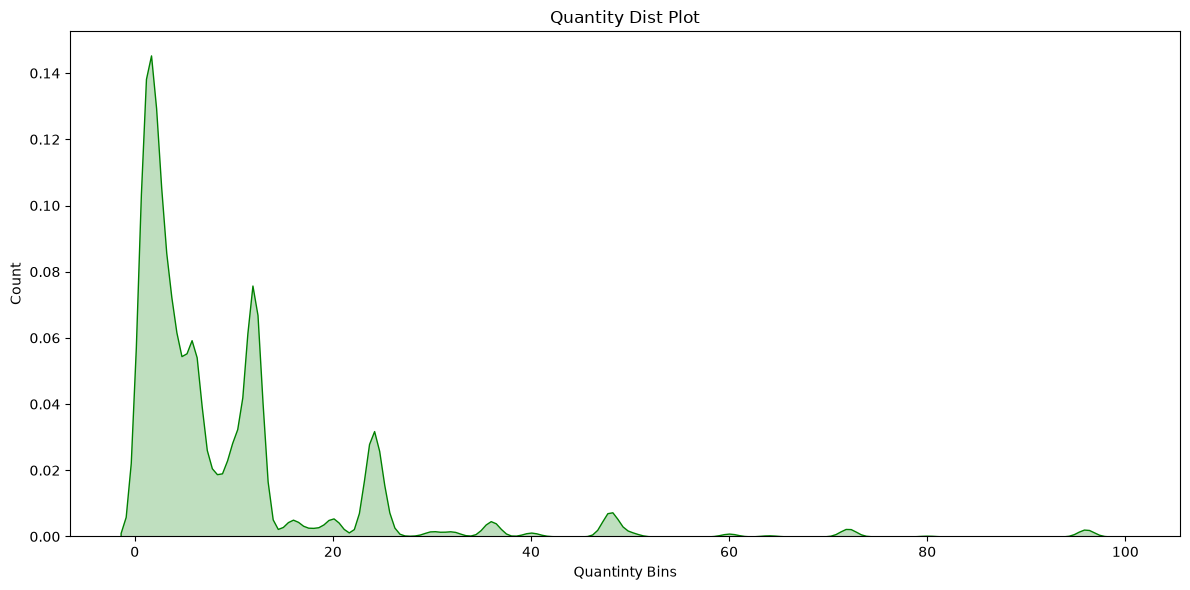

In [26]:
plt.figure(figsize=(12,6))
sns.kdeplot(Quantity_df['Quantity'],fill=True,color='Green')
plt.title("Quantity Dist Plot")
plt.xlabel("Quantinty Bins")
plt.ylabel('Count')
plt.tight_layout()
plt.show()


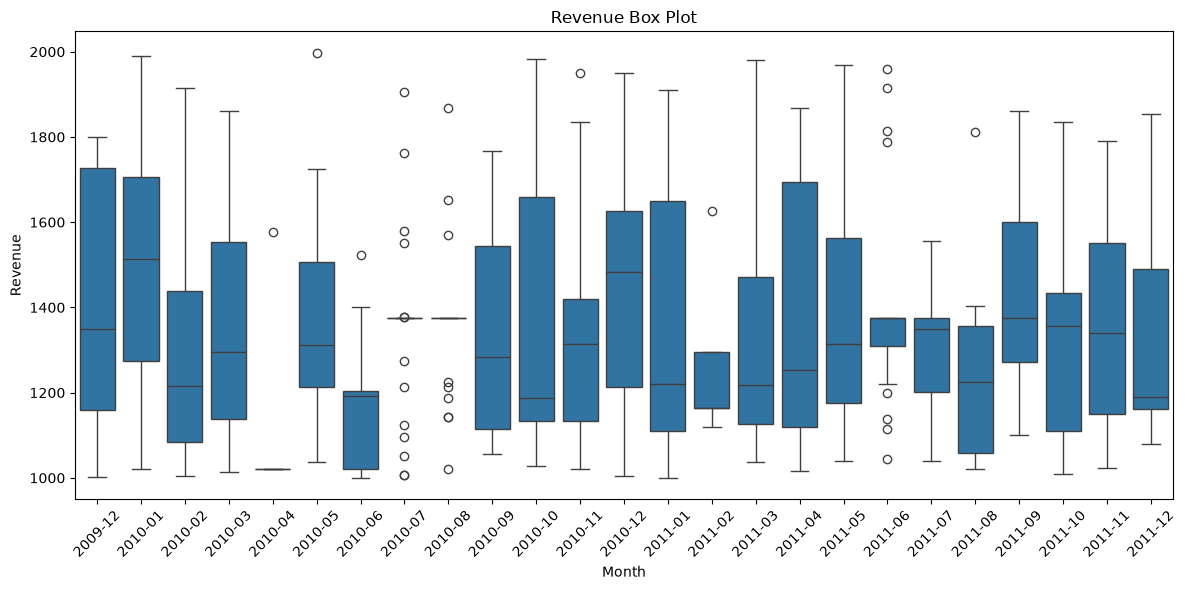

In [27]:
Revenue_df=df[(df["Revenue"]>1000) & (df["Revenue"]<2000)]
plt.figure(figsize=(12,6))
sns.boxplot(data=Revenue_df,x='Month',y='Revenue')
plt.title("Revenue Box Plot")
plt.xlabel("Month")
plt.ylabel('Revenue')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [28]:
df.columns

Index(['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'Price', 'Customer ID', 'Country', 'Month', 'Revenue'],
      dtype='str')

In [29]:
df_2=df.groupby('Country')['Invoice'].nunique().sort_values(ascending=False).head(5)
df_2.head()

Country
United Kingdom    33541
Germany             789
France              614
EIRE                567
Netherlands         228
Name: Invoice, dtype: int64

In [30]:
top_countries=df['Country'].value_counts().head(5).index.to_list()
top_countries

['United Kingdom', 'Germany', 'EIRE', 'France', 'Netherlands']

In [31]:
df_top=df[df['Country'].isin(top_countries)].copy()
df_top

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Month,Revenue
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,2009-12,83.40
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,2009-12,81.00
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,2009-12,81.00
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,2009-12,100.80
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,2009-12,30.00
...,...,...,...,...,...,...,...,...,...,...
1067366,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France,2011-12,12.60
1067367,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France,2011-12,16.60
1067368,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France,2011-12,16.60
1067369,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France,2011-12,14.85


In [32]:
grouped_data=df_top.groupby(['Country','Month'])["Revenue"].sum().reset_index()
grouped_data.head()

,Country,Month,Revenue
0,EIRE,2009-12,18170.46
1,EIRE,2010-01,65031.41
2,EIRE,2010-02,20206.46
3,EIRE,2010-03,22989.46
4,EIRE,2010-04,20668.08


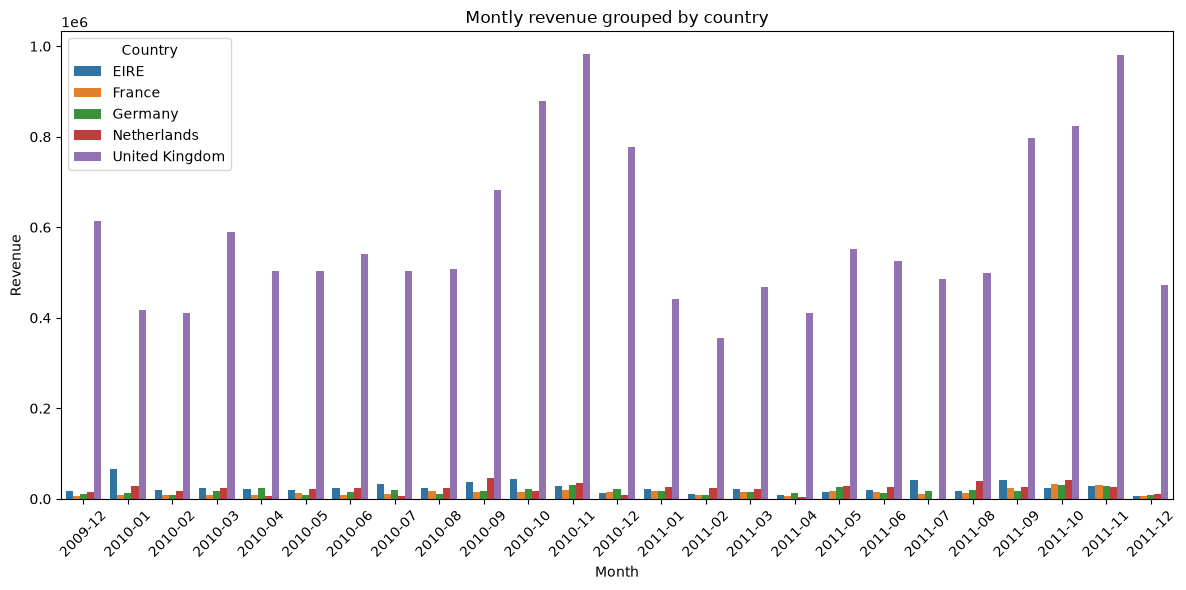

In [33]:
plt.figure(figsize=(12,6))
sns.barplot(data=grouped_data,x='Month',y='Revenue',hue='Country')
plt.title("Montly revenue grouped by country")
plt.xlabel("Month")
plt.ylabel('Revenue')
plt.xticks(rotation=45)
plt.tight_layout()
plt.legend(title='Country')
plt.show()